# KYC Onboarding Agent with LangGraph

When someone opens a bank account, a KYC (Know Your Customer) analyst checks who they are before the bank takes their money. In this workshop you'll build an agent that does the same job:

1. **Extract** the customer's details from their application
2. **Screen** them against a sanctions list and a PEP (Politically Exposed Person) list
3. **Assess** their risk
4. **Route** low-risk customers to automatic approval, and high-risk customers to a human reviewer
5. **Write** a short decision memo for the audit file

All customers and watchlists are fictional and stored as JSONL files in `data/`. The only network call is to the
model.

The project follows a standardised layout as defined by [Managed Deep Agents (MDA) project structure](https://docs.langchain.com/langsmith/python/managed-deep-agents-project-structure):

| Path | What's in it |
|------|--------------|
| `agent.py` | The agent's entry point, exported as `agent`. |
| `tools/` | The lookups the agent uses: applications and watchlist screening. |
| `utils/` | Helper functions. |
| `data/` | The bank's database: one JSONL file per table. |

**How to use this notebook:**

This notebook provides a decomposition of the `agent.py` file and introduces LangGraph concepts that can be used to build complex agents with multiple steps. See the `agent.py` file specifically for a complete end-to-end solution of the agent graph in it's basic form.

## Step 0: Setup (2 min)

Copy `.env.example` to `.env` in the repo root (shared by all three topics) and fill in your gateway key. The
model is reached through the LLM gateway set up there. To use another model, set `MODEL_NAME` as `provider:model`
(for example `openai:gpt-6-luna`).

The model is set up once, in `utils/models.py`, and every module imports it from there. You don't need to edit
that file or this notebook to switch.

In [ ]:
# Notebook only: let Python find `agent.py` and the `utils/` and `tools/` folders.
# This notebook lives in 01_kyc_agent/modules/, so the 01_kyc_agent folder is one level up.
import sys
from pathlib import Path

project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

Check the model responds. If this fails, check the values in your `.env` file.

In [ ]:
from langchain.chat_models import init_chat_model

from utils.models import model

if __name__ == "__main__":
    print(init_chat_model(model).invoke("Say hello to the KYC hackathon in one sentence.").content)

Check your LangSmith instance as configured in the `.env` file to ensure that traces are being received by the instance to the appropriate workspace and project ID.

Your trace will look like this:

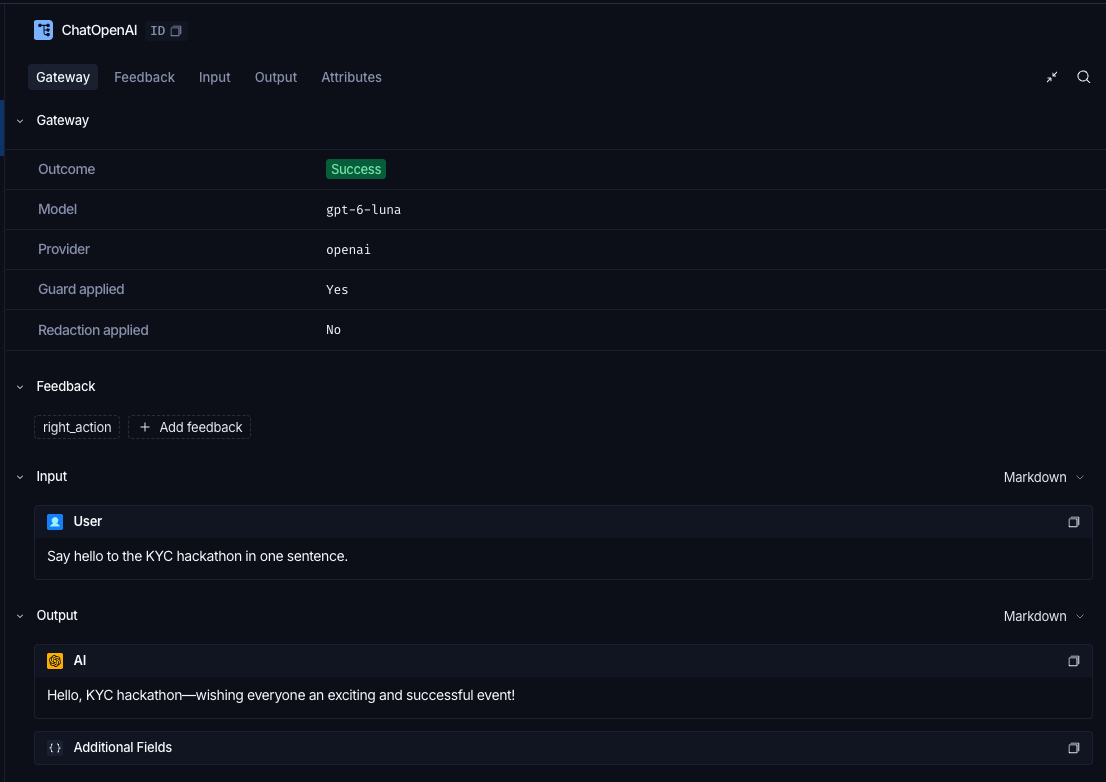

## Step 1: The bank's database (2 min)

The data lives in `data/` as **JSONL** files: one file per table, one JSON object per line, like rows in a
database table. `utils/db.py` reads them for us with three functions:

- `db.table("pep_list")`: every row in a table.
- `db.query("sanctions_list", program="Terrorist financing")`: the rows that match.
- `db.get("applications", customer_id="CUST-002")`: the first row that matches, or `None`.

| Table | What's in it |
|-------|--------------|
| `applications` | Each customer's account application, as free text |
| `sanctions_list` | People under sanctions |
| `pep_list` | Politically exposed people |

Three customers have applied for an account. Each one is written differently, as real applications are.

| Customer | What we expect |
|----------|----------------|
| `CUST-001` | Clean: no watchlist matches |
| `CUST-002` | A government minister: a PEP |
| `CUST-003` | Close to a sanctioned name, but spelled differently |

In [ ]:
from utils import db

if __name__ == "__main__":
    print(db.get("applications", customer_id="CUST-002"), "\n")
    print(f"Watchlists: {len(db.table('sanctions_list'))} sanctioned people, {len(db.table('pep_list'))} PEPs")
    print("First sanctions entry:", db.table("sanctions_list")[0])

`tools/applications.py` has a small function that looks up an application by customer ID. The graph will use
it, so you only ever give it a customer ID, not the whole application.

In [ ]:
from tools.applications import get_application

if __name__ == "__main__":
    print(get_application("CUST-003"))

## Step 2: Extract a customer profile (4 min)

The applications are free text. Before we can screen anyone we need their details as clean, named fields.

We describe the fields we want as a Pydantic model, and `with_structured_output` makes the model fill it in.
The `description` on each field tells the model what to put there.

`method="json_schema"` uses the model provider's native structured output, so the reply always matches the
fields. Newer models, such as Claude Sonnet 5.5, need it.

In [ ]:
from pydantic import BaseModel, Field

class CustomerProfile(BaseModel):
    """Identity details from a customer's account application.
    """
    full_name: str = Field(description="The customer's full name, exactly as written")
    date_of_birth: str = Field(description="Date of birth in YYYY-MM-DD format")
    nationality: str = Field(description="Country of citizenship, e.g. 'British'")
    occupation: str = Field(description="Job title or role")
    source_of_funds: str = Field(description="Where the money they will deposit comes from")

if __name__ == "__main__":
    extractor = init_chat_model(model).with_structured_output(CustomerProfile, method="json_schema")
    profile = extractor.invoke(get_application("CUST-003"))
    print(profile)

## Step 3: Screening checks (3 min)

Screening means comparing the customer's name against watchlists. Names are often spelled differently
("Dmitri Volkonsky" vs "Dmitry Volkonskiy"), so an exact match isn't enough. We score how alike two names are,
from 0 to 1, and treat anything at or above `MATCH_THRESHOLD` as a hit.

The checks live in `tools/screening.py` and read the watchlists from the database. They're plain Python
functions, with no LLM involved. In a real bank they would call a screening provider. Here's the file:

In [ ]:
from tools.screening import check_pep, check_sanctions

if __name__ == "__main__":
    print("Sarah Mitchell:  ", check_sanctions("Sarah Mitchell", "1990-03-14"), check_pep("Sarah Mitchell"))
    print("Viktor Harlan:   ", check_pep("Viktor Harlan"))
    print("Dmitri Volkonsky:", check_sanctions("Dmitri Volkonsky", "1975-09-11"))

## Step 4: State and nodes (5 min)

A LangGraph graph is made of three things:

- **State:** a dictionary that every step can read. We describe its keys with a `TypedDict`.
- **Nodes:** plain Python functions. Each one takes the state and returns *only the keys it wants to update*.
- **Edges:** which node runs next.

Here's the state for one KYC case. `KYCInput` is the graph's input: we only provide `customer_id`, and the
nodes fill in the rest. It's what LangGraph Studio asks you for.

In [ ]:
from typing import TypedDict

class MyAgentContext(TypedDict):
    """The agent configuration context that is not exposed to the user directly.
    
    LangSmith studio will show this under the "assistant" option and it can be used by the assistant API to configure parameters for an instance of the agent.
    """
    agent_model: str

class MyAgentInput(TypedDict):
    """The agent public input schema.

    Callers (and LangSmith Studio) only supply a customer_id; every other state key is filled in by the
    nodes, so exposing just this keeps the input form minimal.
    """
    customer_id: str            # whose application to check, for example "CUST-001"

class MyAgentState(MyAgentInput):
    """The shared state within the agent.

    Every node reads from it and returns only the keys it updates, which LangGraph merges back in, so it
    acts as the case file that carries data between steps of the graph.

    Extends the input to contain additional fields.
    """
    application: str            # the raw application text, looked up by extract_profile
    profile: dict               # set by extract_profile
    screening_hits: list[dict]  # set by screen_customer
    risk_level: str             # "low" or "high", set by assess_risk
    risk_reasons: list[str]     # why we chose that risk level
    decision: str               # "approve" or "reject"
    reviewer: str               # "system" or "human"
    reviewer_notes: str
    decision_memo: str          # set by write_decision

Now the nodes. Each one does one job, using what we built in steps 1 to 3.

In [ ]:
from typing import Literal

#
# Nodes for the agent Graph
#
def extract_profile(state: MyAgentState) -> dict:
    """Turn the customer's free-text application into structured identity details.

    Takes in: `customer_id` from the state.
    Does: looks up the raw application text, then asks the LLM (via `extractor`) to fill in a CustomerProfile.
    Returns: `application` (the raw text) and `profile` (the extracted fields as a plain dict).
    """
    application = get_application(state["customer_id"])

    extractor = init_chat_model(model).with_structured_output(CustomerProfile, method="json_schema")
    profile = extractor.invoke(f"Extract the customer's details from this account application.\n\n{application}")

    return {"application": application, "profile": profile.model_dump()}


def screen_customer(state: MyAgentState) -> dict:
    """Check the customer against the sanctions and PEP watchlists.

    Takes in: `profile` from the state (uses `full_name` and `date_of_birth`).
    Does: runs the fuzzy-match sanctions check (name plus date of birth) and the PEP check (name only).
    Returns: `screening_hits`, a list of every watchlist entry that matched (empty if the customer is clean).
    """
    name = state["profile"]["full_name"]
    hits = check_sanctions(name, state["profile"]["date_of_birth"]) + check_pep(name)
    return {"screening_hits": hits}


def assess_risk(state: MyAgentState) -> dict:
    """Decide whether the customer is low or high risk from the screening results.

    Takes in: `screening_hits` from the state.
    Does: any watchlist hit makes the customer high risk; no hits makes them low risk. Each hit is turned
    into a readable reason for the audit trail.
    Returns: `risk_level` ("low" or "high") and `risk_reasons` (the list of reasons behind that level).
    """
    reasons = [
        f"{hit['list'].upper()} match: {hit['matched_name']} ({hit['details']}), similarity {hit['score']}"
        for hit in state["screening_hits"]
    ]
    if reasons:
        return {"risk_level": "high", "risk_reasons": reasons}
    return {"risk_level": "low", "risk_reasons": ["No watchlist matches"]}


def write_decision(state: MyAgentState) -> dict:
    """Write the short decision memo that goes in the audit file.

    Takes in: `profile`, `screening_hits`, `risk_level`, `decision`, `reviewer` and `reviewer_notes`.
    Does: gives those facts to the LLM and asks for a memo under 120 words, using only what it was given.
    Returns: `decision_memo`, the memo text.
    """
    prompt = f"""
You are a KYC compliance analyst. Write a short decision memo (under 120 words) for the audit file.

Customer profile: {state["profile"]}
Screening hits: {state["screening_hits"] or 'None'}
Risk level: {state["risk_level"]}
Decision: {state["decision"]} (by {state["reviewer"]})
Reviewer notes: {state["reviewer_notes"]}

Say who the customer is, what screening found, the risk level, and the final decision with its reason.
Use only the facts above."""

    return {"decision_memo": init_chat_model(model).invoke(prompt).content}

#
# Routing based on the risk level, determining the next node to run
#
def route_on_risk(state: MyAgentState) -> Literal["auto_approve", "human_review"]:
    """Choose which branch the graph takes after the risk assessment.

    Takes in: `risk_level` from the state.
    Does: sends high-risk customers to a human and everything else to automatic approval.
    Returns: the name of the next node, "human_review" or "auto_approve". It updates no state keys, because it
    is a routing function and not a node.
    """
    if state["risk_level"] == "high":
        return "human_review"
    return "auto_approve"

def auto_approve(state: MyAgentState) -> dict:
    """Approve a low-risk customer without involving a human.

    Takes in: the state, but reads nothing from it; this branch is only reached when `risk_level` is "low".
    Does: records an automatic approval.
    Returns: `decision` ("approve"), `reviewer` ("system") and `reviewer_notes` explaining the approval.
    """
    return {"decision": "approve", "reviewer": "system", "reviewer_notes": "Low risk, approved automatically."}   

Nodes are just functions, so you can call them by hand. Each one returns only the keys it changed.

In [ ]:
import json

if __name__ == "__main__":
    input = '{ "customer_id": "CUST-002" }'

    state = MyAgentState(json.loads(input))

    for node in (extract_profile, screen_customer, assess_risk):
        state |= node(state)

    print("state: ", json.dumps(state))
    print()
    print(state["risk_level"], state["risk_reasons"])
    print("Next node:", route_on_risk(MyAgentState(**state)))

## Step 5: Human in the loop (4 min)

A bank won't let an agent approve a sanctions or PEP match on its own. A compliance officer has to decide.

`interrupt()` pauses the graph and hands a question to whoever is running it. The graph waits, for minutes or
days, until it is resumed with an answer. That answer becomes the return value of `interrupt()`.

The routing function decides which branch to take after `assess_risk`. It returns the *name of the next node*.
The `Literal[...]` type tells LangGraph which nodes it can return, so it can draw the branch.

NOTE: Interrupt requires a runnable context, so it will not work outside of an agent invoke. To be able to resume, the checkpointer needs to be enabled, to continue the execution of the graph once an interrupt has occurred. Hence our graph is configured with an in memory checkpointer.

In [ ]:
from langgraph.types import interrupt

def human_review(state: MyAgentState) -> dict:
    """Pause the graph so a compliance officer can decide on a high-risk customer.

    Takes in: `profile` (for the customer's name) and `risk_reasons` from the state.
    Does: calls `interrupt()`, which stops the graph and hands the reviewer a question. The graph waits until
    it is resumed with an answer shaped like {"decision": ..., "notes": ...}, which becomes the return value
    of `interrupt()`.
    Returns: `decision` (the reviewer's choice), `reviewer` ("human") and `reviewer_notes` (their notes).
    """
    answer = interrupt(
        {
            "customer": state["profile"]["full_name"],
            "risk_reasons": state["risk_reasons"],
            "question": "Approve or reject this customer? Reply with {'decision': ..., 'notes': ...}",
        }
    )
    return {"decision": answer["decision"], "reviewer": "human", "reviewer_notes": answer.get("notes", "")}


## Step 6: Build the graph (2 min)

Add each node, then the edges between them. `add_conditional_edges` uses `route_on_risk` to pick the branch.

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph

#
# LangGraph Agent Definition
#
def build_agent(**kwargs):
    builder = StateGraph(state_schema=MyAgentState, context_schema=MyAgentContext, input_schema=MyAgentInput)

    builder.add_node("extract_profile", extract_profile)
    builder.add_node("screen_customer", screen_customer)
    builder.add_node("assess_risk", assess_risk)
    builder.add_node("auto_approve", auto_approve)
    builder.add_node("human_review", human_review)
    builder.add_node("write_decision", write_decision)

    builder.add_edge(START, "extract_profile")
    builder.add_edge("extract_profile", "screen_customer")
    builder.add_edge("screen_customer", "assess_risk")
    builder.add_conditional_edges("assess_risk", route_on_risk)
    builder.add_edge("auto_approve", "write_decision")
    builder.add_edge("human_review", "write_decision")
    builder.add_edge("write_decision", END)

    return builder.compile(**kwargs)

# Define the agent with an in memory checkpointer
agent = build_agent(checkpointer=InMemorySaver())

`agent` is what LangGraph Studio and `langgraph dev` load (see `langgraph.json`). Let's draw it.

In [ ]:
if __name__ == "__main__":
    try:
        from IPython.display import Image, display

        display(Image(agent.get_graph().draw_mermaid_png()))
    except Exception:
        print(agent.get_graph().draw_mermaid())

## Step 7: Run it (3 min)

To pause and resume, the graph needs somewhere to save its progress. That's a **checkpointer**. We compile a
second copy, `app`, with an in-memory checkpointer. (LangGraph Studio provides its own, which is why `agent`
above has none.)

Each customer case gets a `thread_id`, so the checkpointer knows which saved progress to resume.

First, the clean customer. It should go straight through.

In [ ]:
if __name__ == "__main__":
    config = {"configurable": {"thread_id": "CUST-001"}}
    result = agent.invoke({"customer_id": "CUST-001"}, config)
    print(f"Risk: {result['risk_level']}  Decision: {result['decision']} (by {result['reviewer']})\n")
    print(result["decision_memo"])

Now the near-match on the sanctions list. The graph should pause at `human_review` and show us its question.

In [ ]:
if __name__ == "__main__":
    config = {"configurable": {"thread_id": "CUST-003"}}
    result = agent.invoke({"customer_id": "CUST-003"}, config)
    print("Paused at:", agent.get_state(config).next)
    print(result["__interrupt__"][0].value)

You're the compliance officer. Make your decision and resume the graph with `Command(resume=...)`.
To try a different decision, run the cell above again, then change `reviewer_answer` and run this one.

In [ ]:
from langgraph.types import Command

if __name__ == "__main__":
    reviewer_answer = {"decision": "reject", "notes": "Strong match to a sanctioned person, and the date of birth matches."}
    result = agent.invoke(Command(resume=reviewer_answer), config)
    print(f"Decision: {result['decision']} (by {result['reviewer']})\n")
    print(result["decision_memo"])

Finally, run every customer in the `applications` table. For high-risk customers, a stand-in reviewer rejects
sanctions matches and approves PEPs with extra monitoring, so the batch runs without stopping.

In [ ]:
if __name__ == "__main__":
    for row in db.table("applications"):
        customer_id = row["customer_id"]
        config = {"configurable": {"thread_id": f"batch-{customer_id}"}}
        result = agent.invoke({"customer_id": customer_id}, config)

        if "__interrupt__" in result:
            if any(hit["list"] == "sanctions" for hit in result["screening_hits"]):
                answer = {"decision": "reject", "notes": "Sanctions match."}
            else:
                answer = {"decision": "approve", "notes": "PEP accepted with enhanced monitoring."}
            result = agent.invoke(Command(resume=answer), config)

        print(
            f"{customer_id}  {result['profile']['full_name']:<18} risk={result['risk_level']:<5} "
            f"decision={result['decision']:<8} by={result['reviewer']}"
        )

## Done! Where to look next

- **LangGraph Studio:** run `uv run langgraph dev` in the `01_kyc_agent` folder. Allows you to debug a graph at each node.

## Next Steps:

1. **Add Memory.** Setup memory for the agent. See link: https://docs.langchain.com/oss/python/concepts/memory
2. **Deploy The Agent.** Use `uv run langgraph deploy` to deploy your agent into LangSmith.
3. **Use LangSmith to add evals.** Setup evals for offline experimentation, to assert behaviour.
4. **Use Alternative models.** Use smaller models for lighter weight parts of the agent and update configuration to allow users to choose the models.

## Extending the agent:
1. **Let the agent choose its checks.** Turn `check_sanctions` and `check_pep` in `tools/screening.py` into
   `@tool`s and let an agent decide which to call.
2. **Add a medium-risk level.** For example, large deposits or a high-risk occupation trigger extra checks
   without a full human review.
3. **Adverse media.** Add a `news_articles.jsonl` table and a search in `tools/`, and flag customers with
   negative coverage.
4. **Screen faster.** Run the sanctions and PEP checks as two parallel nodes.
5. **Businesses.** Screen a company and the people who own it.